# 16 - The confident chatbot: token probabilities, stated confidence and exchangeability for language models

> "When Quill says it is 95% sure, how often is it right - and if we measure that once, does it stay true?" - Quill head of learning

The question has two halves, and they need different tools. The first half is about calibration: does "95% sure" mean that 95 of every 100 such answers are right? That can be checked with data, and the check is notebook 04's reliability check. The second half decides whether any of it can be used. A number measured once, on one batch of questions, carries over to tomorrow's questions only if tomorrow's questions, answered tomorrow, are exchangeable with today's (notebook 09). For a language model that takes more than "similar students": the model version, the prompt, the decoding settings and even the order in which the options are shown all helped produce the number. So the sharper statistical question is this. A language model can report how sure it is in three ways: how well calibrated is each, which of them best separates the questions it gets right from the ones it gets wrong, and what has to stay fixed for a calibration, or a conformal guarantee built on one, to carry over?

This notebook opens Part III of the course, and with it a new story. **Quill Learning** is a fictional education company. Its AI study assistant, Quill, answers exam-practice multiple-choice questions, writes short explainers (in this course, profiles of the chemical elements) and answers questions from a library of encyclopedia passages it retrieves. Quill runs on a hosted language model. Four people at Quill care how sure it is: the head of learning, because students must not be misled; the product lead, who wants shortlists and honest uncertainty in the interface; the content lead, who must not publish false facts; and the platform lead, who pays for every passage sent to the model. Notebooks 16 and 17 serve the first two, notebook 18 the content lead and notebook 19 the platform lead.

Part I opened with a confident model that lost money on simulated houses. Part III opens with a confident chatbot, and this time nothing is simulated. Every model output in Part III is real: `gpt-4.1-mini` on Azure OpenAI, queried once by `llm_data/generate_llm_data.ipynb` and cached as CSV files. The generator notebook writes out every prompt next to the code that sent it, and `llm_data/README.md` records the model, the sources and their licences. Nothing in these notebooks calls a model, and you need no API key. Section 1 explains why the caching is itself a lesson about exchangeability.

**What you will learn**

- The three ways a language model reports how sure it is (token probability, stated confidence, agreement of repeated samples), and how to check each with a reliability diagram and one number (field guide §24).
- Why calibration and ranking are different properties of a score, why conformal coverage needs neither, and why short shortlists need the second.
- Why even a perfectly calibrated probability promises nothing about the question in front of a student, and how one corrected quantile turns token probabilities into a shortlist with a 90% coverage promise.
- What must stay fixed between calibration and use, the procedure, measured on four real changes: the same prompt sent again, a new prompt, shuffled options and a new mix of subjects (field guide §25 and §26).
- What to write in the calibration record, so that a guarantee can be traced to the procedure that earned it.

**Where we are in the series.** Part II ended with notebook 15, which held coverage on target under drift without assuming exchangeability. Part III returns to split conformal prediction and asks what exchangeability means when the model sits behind someone else's API. This notebook leans on notebook 02 (the corrected quantile), notebook 03 (the coverage lottery and the marginal guarantee), notebook 04 (the reliability check and LAC sets) and notebook 09 (exchangeability at a level, and the ways it breaks). Notebook 17 then builds the shortlist properly from these same probabilities: LAC and APS sets, sets when an API gives no probabilities, and coverage subject by subject.

In [1]:
import hashlib
import json
import math
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, binomtest, chi2_contingency, chisquare

from sklearn.metrics import roc_auc_score

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the product's 90% promise

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)

## 1. Three ways a model tells you how sure it is

Quill's practice bank for this part of the course is 2,513 multiple-choice questions from 28 subjects of MMLU (Hendrycks et al., 2021), a public benchmark of exam questions that runs from elementary mathematics to international law. Each question has four options and one right answer. The generator sampled 90 questions per subject; Azure's content filter refused 7 history questions, and those were dropped from every variant, so every question below has every reading. For each question we have three readings of how sure the model is, each from its own request:

1. **Token probability.** The model is asked for the letter only, at temperature 0 (always pick the most likely token), and the API returns the log-probabilities of the 20 most likely first tokens of the reply. Exponentiate those that spell `A`, `B`, `C` or `D` (the generator counts a letter in any token form: with a leading space or tab, in lower case, or followed by "." or ")") and renormalize them to sum to one, and you have four option probabilities (`base_pA` to `base_pD`). A letter that is not among the 20 tokens gets probability 0, which only means that it was not in the top 20: every token the API left out is at most as likely as the 20th (`base_top20_floor`). The reading is the probability of the top letter, and the answer it is graded on is that letter.
2. **Stated (verbalized) confidence.** A separate request asks for a JSON reply holding an answer and "your probability, in percent, that your answer is correct" (`verbal_answer`, `verbal_confidence`). This is the number a chat interface would show if you simply asked the model how sure it is.
3. **Agreement (self-consistency).** Ten answers sampled at temperature 1.0 (`samples_A` to `samples_D`, and `samples_invalid` for samples that were not a letter). The answer is the most frequent letter, and the reading is the share of the ten samples that gave it.

Before any number, a word on why the files are cached. A hosted model is not bit-for-bit reproducible, even at temperature 0 with the API's `seed` parameter set; the generator set both, and section 4 measures how much the answers still move. Asking again would hand you a different sample of answers, so the cached files are the reference for the course. That decision is an exchangeability statement, the first of many in Part III. Our calibration questions and our test questions were answered by one procedure, in one generation run (the log dates it 2026-11-07), and frozen in one cache: the friendliest situation the guarantee can ever have. Production never gets it for free. The live model answers tomorrow, under a deployment name whose underlying model the provider may update, with whatever prompt the product team shipped last week. Every calibration in Part III is a statement about the cached procedure, and section 5 lists what to write down so that the statement can be checked later.

In [2]:
questions = pd.read_csv("llm_data/mmlu_questions.csv")
outputs = pd.read_csv("llm_data/mmlu_llm_outputs.csv")
with open("llm_data/generation_log.json") as f:
    generation_log = json.load(f)
mcq = questions.merge(outputs, on="qid", validate="one_to_one")
assert len(mcq) == len(questions) == len(outputs), "every question needs exactly one row of model outputs"

LETTERS = ["A", "B", "C", "D"]
VARIANTS = ["base", "rerun", "shuffled", "altprompt"]
y = mcq["answer"].map({letter: k for k, letter in enumerate(LETTERS)}).to_numpy()
n_q = len(mcq)
rows = np.arange(n_q)

# One (questions x 4) array of option probabilities per procedure, always in the ORIGINAL
# letter order (the generator mapped the shuffled run back), so column k means option k
# everywhere and the right answer is column y.
probs = {v: mcq[[f"{v}_p{L}" for L in LETTERS]].to_numpy() for v in VARIANTS}
for v, p in probs.items():
    assert np.allclose(p.sum(axis=1), 1.0, atol=1e-5), f"{v}: probabilities must be renormalized over A-D"

# Reading 1, token probability: the top letter's probability at temperature 0.
token_conf = probs["base"].max(axis=1)
token_right = probs["base"].argmax(axis=1) == y
# Reading 2, stated confidence, from a separate JSON request. An answer that is not a
# letter is graded wrong: the instruction asked for a letter.
stated_conf = mcq["verbal_confidence"].to_numpy() / 100
stated_right = (mcq["verbal_answer"] == mcq["answer"]).to_numpy()
# Reading 3, agreement: the share of 10 samples at temperature 1.0 that gave the modal
# letter. argmax breaks a tie at the mode alphabetically; a question without a single
# valid sample has agreement 0 and counts as wrong.
counts = mcq[[f"samples_{L}" for L in LETTERS]].to_numpy()
agree_conf = counts.max(axis=1) / 10
agree_right = (counts.argmax(axis=1) == y) & (counts.max(axis=1) > 0)
mode_ties = ((counts == counts.max(axis=1, keepdims=True)).sum(axis=1) > 1) & (counts.max(axis=1) > 0)
# Ties for the top token probability (equal log-probabilities): argmax takes the first letter there too.
top_ties = (probs["base"] == token_conf[:, None]).sum(axis=1) > 1
key_tied_top = top_ties & (probs["base"][rows, y] == token_conf)

# MMLU's own subject categories (Hendrycks et al. 2021): these 10 of our 28 subjects are STEM.
MMLU_STEM = {"abstract_algebra", "astronomy", "college_computer_science", "college_mathematics",
             "college_physics", "elementary_mathematics", "high_school_chemistry",
             "high_school_physics", "high_school_statistics", "machine_learning"}
is_stem = mcq["subject"].isin(MMLU_STEM).to_numpy()

# Small print: answers that do not follow the requested format. The generator kept only the
# FIRST character of the stated answer, so a reply of "24%" is stored as "2": an exact match with
# the right option's text is a lower bound, a match with its first character an upper bound.
non_letter = ~mcq["verbal_answer"].isin(LETTERS)
right_text = [str(mcq.at[i, mcq.at[i, "answer"]]).strip() for i in np.flatnonzero(non_letter)]
stored = mcq.loc[non_letter, "verbal_answer"].astype(str).tolist()
value_right_exact = sum(t == s for t, s in zip(right_text, stored))
value_right_first = sum(t[:1] == s for t, s in zip(right_text, stored))
invalid_rows = mcq["samples_invalid"] > 0
invalid_subjects = mcq.loc[invalid_rows, "subject"].value_counts()
subject_acc = pd.Series(token_right).groupby(mcq["subject"]).mean().sort_values(kind="mergesort")

print(f"{n_q:,} questions from {mcq['subject'].nunique()} subjects; model "
      f"{generation_log['chat_deployment']}, generated {generation_log['generated_on']}")
print(f"median raw probability mass on the four letters (base prompt): "
      f"{mcq['base_letter_mass'].median():.3f}")
print(f"stated answer equals the top token letter on "
      f"{(mcq['verbal_answer'].to_numpy() == np.array(LETTERS)[probs['base'].argmax(axis=1)]).mean():.1%}"
      f" of questions")
print(f"stated answers that are not a letter: {non_letter.sum()}, digits: "
      f"{mcq.loc[non_letter, 'verbal_answer'].astype(str).str.isdigit().sum()} (graded wrong; "
      f"{value_right_exact} equal the right option's text, {value_right_first} its first character)")
print(f"samples that were not a letter: {int(mcq['samples_invalid'].sum())} of {10 * n_q:,}, on "
      f"{invalid_rows.sum()} questions ({invalid_subjects.iloc[0]} college_mathematics, "
      f"{invalid_subjects.get('formal_logic', 0)} formal_logic, {invalid_rows.sum() - invalid_subjects.iloc[:2].sum()} other); "
      f"{(counts.sum(axis=1) == 0).sum()} questions without a single letter; ties at the mode: {mode_ties.sum()}")
print(f"ties for the top token probability: {top_ties.sum()} questions; answer key among the tied on "
      f"{key_tied_top.sum()}, graded wrong on {(key_tied_top & ~token_right).sum()} of them")
print("lowest subject accuracy:  " + ", ".join(f"{s} {a:.3f}" for s, a in subject_acc.head(3).items()))
print("highest subject accuracy: " + ", ".join(f"{s} {a:.3f}" for s, a in subject_acc.tail(4).items()))
print(f"accuracy on MMLU's STEM subjects: {token_right[is_stem].mean():.3f} ({is_stem.sum()} questions); "
      f"on the others: {token_right[~is_stem].mean():.3f} ({(~is_stem).sum()} questions)")

readings = pd.DataFrame({
    "accuracy of its answer": [token_right.mean(), stated_right.mean(), agree_right.mean()],
    "mean confidence": [token_conf.mean(), stated_conf.mean(), agree_conf.mean()],
}, index=["token probability", "stated confidence", "agreement of 10 samples"])
readings["overconfidence"] = readings["mean confidence"] - readings["accuracy of its answer"]
readings.round(3)

2,513 questions from 28 subjects; model gpt-4.1-mini, generated 2026-11-07
median raw probability mass on the four letters (base prompt): 1.000
stated answer equals the top token letter on 93.4% of questions
stated answers that are not a letter: 10, digits: 10 (graded wrong; 4 equal the right option's text, 7 its first character)
samples that were not a letter: 85 of 25,130, on 19 questions (10 college_mathematics, 4 formal_logic, 5 other); 3 questions without a single letter; ties at the mode: 22
ties for the top token probability: 3 questions; answer key among the tied on 3, graded wrong on 2 of them
lowest subject accuracy:  college_mathematics 0.533, moral_scenarios 0.556, global_facts 0.622
highest subject accuracy: astronomy 0.922, high_school_geography 0.922, sociology 0.922, us_foreign_policy 0.922
accuracy on MMLU's STEM subjects: 0.732 (900 questions); on the others: 0.834 (1613 questions)


,accuracy of its answer,mean confidence,overconfidence
token probability,0.797,0.964,0.166
stated confidence,0.797,0.942,0.145
agreement of 10 samples,0.799,0.962,0.163


All three readings agree on the headline. Quill is right on 0.797 of the questions by its token probability, 0.797 by its stated answer and 0.799 by the majority of ten samples. All three also claim far more than that: the chosen letter's token probability averages 0.964, the stated confidence 0.942 and the agreement 0.962, between 14.5 and 16.6 points above the hit rate. The answers themselves mostly coincide (the stated answer equals the top token letter on 93.4% of questions), so these are three opinions about nearly the same answers, not three different students.

The small print is worth reading, because every item in it is a property of the procedure rather than of the model. Ten stated answers came back as a digit instead of a letter: the model wrote an option's value (`3` where the option labelled C reads "3"), and the generator kept only the first character of the reply, so a "24%" would be stored as `2`. We grade all ten as wrong, the strict reading of the instruction, although at least 4 of them named the right option (4 match its text exactly, and 7 match its first character). Of the 25,130 sampled answers, 85 were not a letter, concentrated on 19 questions (10 of them college mathematics and 4 formal logic), and 3 questions produced no letter in ten tries, so their agreement is 0; on 22 questions the samples tied for the most frequent letter, and we break those ties alphabetically. The token probabilities have 3 such ties for the top letter; `argmax` takes the first letter there too, so 2 of them are graded wrong although the answer key shares the top probability. Accuracy also varies a lot by subject, from 0.533 in college mathematics and 0.556 in moral scenarios to 0.922 in four subjects (astronomy, high-school geography, sociology and US foreign policy); on MMLU's own STEM subjects it is 0.732, on the rest 0.834. Keep that spread in mind: section 4 turns it into the largest exchangeability failure in this notebook.

Three questions show what the readings look like one at a time.

In [3]:
# Three questions picked by hand: certain and right, certain and wrong, hesitant.
for qid in ["mmlu_0030", "mmlu_0154", "mmlu_0753"]:
    i = int(np.flatnonzero(mcq["qid"] == qid)[0])
    print(f"{qid} ({mcq.at[i, 'subject']}): {mcq.at[i, 'question']}")
    print("   options: " + " | ".join(f"{L} {mcq.at[i, L]}" for L in LETTERS)
          + f"   -> right answer {mcq.at[i, 'answer']}")
    print("   token probabilities: " + "  ".join(f"{L} {p:.3f}" for L, p in zip(LETTERS, probs["base"][i]))
          + f"   | stated: {mcq.at[i, 'verbal_answer']} at {mcq.at[i, 'verbal_confidence']:.0f}"
          + "   | 10 samples: " + " ".join(f"{L}{int(c)}" for L, c in zip(LETTERS, counts[i])))

mmlu_0030 (abstract_algebra): The inverse of -i in the multiplicative group, {1, -1, i , -i} is
   options: A 1 | B -1 | C i | D -i   -> right answer C
   token probabilities: A 0.000  B 0.000  C 1.000  D 0.000   | stated: C at 100   | 10 samples: A0 B0 C10 D0
mmlu_0154 (college_mathematics): Suppose today is Wednesday. What day of the week will it be 10^(10^(10)) days from now?
   options: A Sunday | B Monday | C Tuesday | D Wednesday   -> right answer A
   token probabilities: A 0.000  B 0.000  C 0.001  D 0.999   | stated: D at 95   | 10 samples: A0 B0 C0 D10
mmlu_0753 (elementary_mathematics): Each story of a building is 14.3 feet tall. If the height of the building is 185.9 feet, how many floors does the building have?
   options: A 10 | B 13 | C 17 | D 9   -> right answer B
   token probabilities: A 0.000  B 0.438  C 0.562  D 0.000   | stated: C at 95   | 10 samples: A0 B6 C4 D0


Three questions, three personalities. On the group-inverse question everything is certain and right. On the Wednesday question (today is Wednesday; what day is it $10^{10^{10}}$ days from now?) everything is certain and wrong: token probability 0.999 on Wednesday, stated confidence 95, ten samples out of ten, and the answer is Sunday. Asking again would not have revealed it. On the building question the model hesitates, 0.562 against 0.438 between 17 and 13 floors, and its stated confidence is still 95. The samples split 6 to 4, and their majority is the right answer. Stated confidence did not register the hesitation that the token probabilities and the samples both show. The three readings side by side:

| Reading | How it is obtained | What it gets wrong here | Common beginner mistake |
|---|---|---|---|
| token probability | log-probabilities of the first answer token, renormalized over A-D | piles up at the top: 76.1% of questions get 0.999 or more | quoting it for an answer that was not the first token (a reasoning chain, a reformatted reply) |
| stated confidence | the model writes a number when asked | a few round numbers, crowded at the top whatever the truth: 95 on 65.8% of questions | reading "95" as a probability |
| agreement of samples | share of 10 samples at temperature 1.0 that give the modal answer | only 11 possible values, and 86.2% of questions at 10 out of 10 | sampling at temperature 0, where every sample is the same, or too few times to break ties |

The percentages in the middle column are printed in the next section.

## 2. Reliability diagrams

Plain words first. Take every answer for which the model claimed about 0.8, and count how many were right. If about 80% were, the reading is **calibrated** at 0.8. Do the same at every level and you have notebook 04's reliability check, drawn as a **reliability diagram**: claimed confidence on the horizontal axis, observed accuracy on the vertical, and the diagonal as the line a calibrated reading would follow. Points below the diagonal are overconfidence, points above it underconfidence. Calibration is a property of groups of answers, never of one answer.

One caution about vocabulary: a calibrated probability (this section) and a calibration set (notebook 02) are unrelated ideas that happen to share a word. Conformal prediction uses a calibration set. It does not need calibrated probabilities, as section 3 shows.

To compress a diagram into one number we use the **expected calibration error (ECE)**: the distance between claimed confidence and observed accuracy, group by group, averaged with weights proportional to how many answers each group holds. In symbols, after the words:

$$\mathrm{ECE} = \sum_{b} \frac{n_b}{n}\,\bigl|\bar c_b - \bar a_b\bigr|,$$

where the sum runs over the groups $b$, $n_b$ is the number of answers in group $b$, $n$ the total number of answers, $\bar c_b$ the mean claimed confidence in the group and $\bar a_b$ the share of its answers that were right. Zero means calibrated at the resolution of the groups. We group token probabilities into ten bins of width 0.1, and give stated confidence and agreement one group per distinct value, since each takes only a handful of values.

Calibration is not the only property that matters, and for conformal prediction it is not even required: section 3 shows that coverage holds for any score. What decides whether the shortlists are short is ranking. A confidence score earns its keep by ranking: right answers should tend to get higher confidence than wrong ones. The **AUROC** (area under the ROC curve) measures exactly that in one number: the probability that a randomly chosen right answer gets a higher confidence than a randomly chosen wrong one, ties counting half. 0.5 is a coin flip and 1.0 a perfect ranking. We report both numbers for each reading.

In [4]:
def reliability_table(confidence, correct, edges=None):
    """Claimed confidence against the hit rate, group by group.

    edges=None makes one group per distinct value, the right choice for stated confidence and
    agreement, which take a handful of values; otherwise answers are binned by `edges`.
    """
    confidence = np.asarray(confidence, dtype=float)
    if edges is None:
        group = confidence
    else:                                  # label each bin by its lower edge; the top bin includes 1.0
        edges = np.asarray(edges, dtype=float)
        group = edges[np.clip(np.digitize(confidence, edges[1:-1]), 0, len(edges) - 2)]
    table = (pd.DataFrame({"group": group, "confidence": confidence, "correct": correct})
             .groupby("group")
             .agg(n=("correct", "size"), confidence=("confidence", "mean"), accuracy=("correct", "mean")))
    table["gap"] = table["confidence"] - table["accuracy"]   # positive = overconfident
    return table.reset_index()


def expected_calibration_error(table):
    """Average |confidence - accuracy| over the groups, weighted by group size."""
    return float((table["n"] * table["gap"].abs()).sum() / table["n"].sum())


READINGS = {
    "token probability": (token_conf, token_right, np.linspace(0, 1, 11)),
    "stated confidence": (stated_conf, stated_right, None),
    "agreement of 10 samples": (agree_conf, agree_right, None),
}
tables, summary = {}, []
for name, (conf, right, edges) in READINGS.items():
    tables[name] = reliability_table(conf, right, edges)
    values, value_counts = np.unique(conf, return_counts=True)
    summary.append({
        "reading": name, "accuracy": right.mean(), "mean confidence": conf.mean(),
        "ECE": expected_calibration_error(tables[name]), "AUROC": roc_auc_score(right, conf),
        "distinct values": len(values), "most common value": values[value_counts.argmax()],
        "share at that value": value_counts.max() / n_q,
    })
    print(f"{name}:")
    print(tables[name].round(3).to_string(index=False))
    print()

fine = reliability_table(token_conf, token_right)
print(f"token probability ECE with one group per distinct value ({len(fine)} groups) "
      f"instead of 10 bins: {expected_calibration_error(fine):.3f}")
very_sure, top_bin = token_conf >= 0.999, token_conf >= 0.9
print(f"inside the top token bin: probability >= 0.999 on {very_sure.sum()} answers ({very_sure.mean():.1%}), right "
      f"{token_right[very_sure].mean():.3f}; 0.9 to 0.999 on {(top_bin & ~very_sure).sum()}, right "
      f"{token_right[top_bin & ~very_sure].mean():.3f}")
print(f"stated confidence of 90 or more: {(stated_conf >= 0.9).sum()} answers ({np.mean(stated_conf >= 0.9):.1%})")
token_conf_6 = np.round(probs["base"], 6).max(axis=1)        # the same probabilities kept to six decimals
print(f"token probability rounded to six decimals: AUROC {roc_auc_score(token_right, token_conf_6):.3f}, "
      f"{np.mean(token_conf_6 == 1.0):.1%} of answers tied at exactly 1")
pd.DataFrame(summary).set_index("reading").round(3)

token probability:
 group    n  confidence  accuracy    gap
   0.3    2       0.372     0.000  0.372
   0.4   23       0.469     0.565 -0.097
   0.5   42       0.551     0.333  0.218
   0.6   63       0.642     0.429  0.214
   0.7   64       0.750     0.453  0.297
   0.8   73       0.849     0.384  0.466
   0.9 2246       0.996     0.843  0.153

stated confidence:
 group    n  confidence  accuracy    gap
  0.00    1        0.00     1.000 -1.000
  0.70    2        0.70     0.500  0.200
  0.75    1        0.75     0.000  0.750
  0.80    2        0.80     0.500  0.300
  0.85  101        0.85     0.554  0.296
  0.90  449        0.90     0.742  0.158
  0.95 1654        0.95     0.818  0.132
  0.99    9        0.99     0.889  0.101
  1.00  294        1.00     0.850  0.150

agreement of 10 samples:
 group    n  confidence  accuracy    gap
   0.0    3         0.0     0.000  0.000
   0.1    2         0.1     0.500 -0.400
   0.3    3         0.3     0.000  0.300
   0.4    7         0.4     0.286

,accuracy,mean confidence,ECE,AUROC,distinct values,most common value,share at that value
reading,,,,,,,
token probability,0.797,0.964,0.168,0.823,2014,1.00,0.066
stated confidence,0.797,0.942,0.146,0.576,9,0.95,0.658
agreement of 10 samples,0.799,0.962,0.164,0.665,10,1.00,0.862


Start with the bottom table, the one-number view. The three ECEs are 0.168 (token probability), 0.146 (stated confidence) and 0.164 (agreement), and each is essentially the reading's overall overconfidence from section 1 (0.166, 0.145, 0.163). That is no coincidence. The overall gap is the same weighted average of the group gaps with their signs kept, so the two numbers agree exactly when every group errs on the same side, and here nearly every group does: the `gap` columns are never negative except for 23 token answers near 0.47, the single answer stated at confidence 0, and two questions whose samples agreed only 1 out of 10. So ECE says one thing on this data, "overconfident by about 15 to 17 points", and nothing about which reading is more useful. It also depends on the grouping: the same token probabilities score 0.197 with one group per distinct value (2,014 groups, most of them a single answer) instead of ten bins.

The AUROC column says something ECE cannot. Token probability ranks right above wrong answers with AUROC 0.823, agreement 0.665 and stated confidence 0.576, barely better than a coin. Part of the token probability's ranking lives in its last digits: kept to six decimals, the same probabilities tie 63.8% of answers at exactly 1 and the AUROC drops to 0.812. Stated confidence has the lowest calibration error and the worst ranking: calibration error and ranking quality are different properties, and the number you most want to quote (the stated one, because it is the easiest to get) is the one that knows least about which answers are wrong. The tables show why: 65.8% of stated confidences are exactly 95 and 86.2% of sample sets agree ten out of ten, while the token probabilities, although 76.1% of them are 0.999 or more, take 2,014 distinct values. The diagrams make this visible.

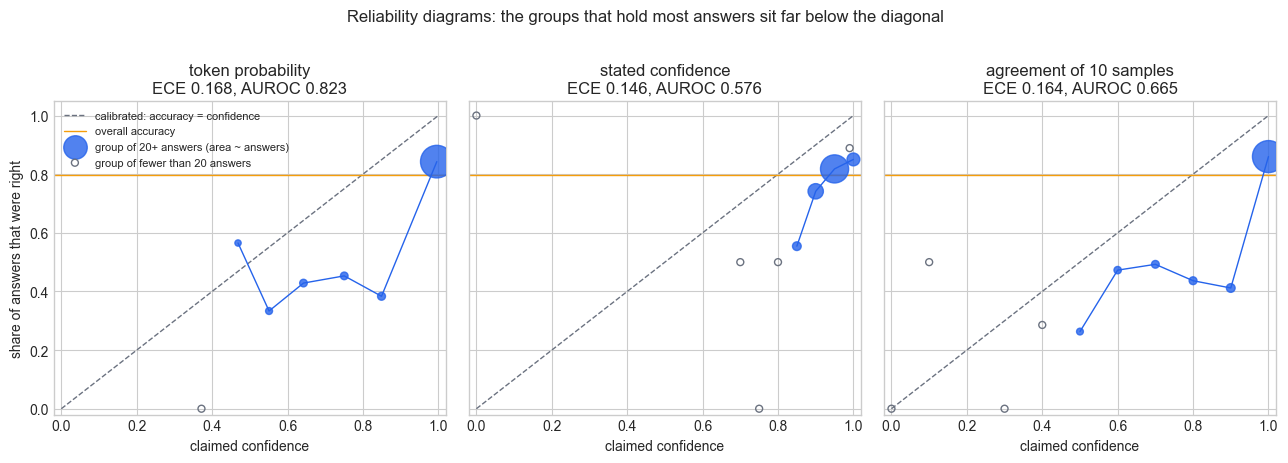

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
for ax, (name, table), row in zip(axes, tables.items(), summary):
    big = table["n"] >= 20                 # a group of a handful of answers is noise, drawn hollow
    ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1, label="calibrated: accuracy = confidence")
    ax.axhline(row["accuracy"], color=AMBER, linewidth=1, label="overall accuracy")
    ax.plot(table.loc[big, "confidence"], table.loc[big, "accuracy"], color=BLUE, linewidth=1, zorder=2)
    ax.scatter(table.loc[big, "confidence"], table.loc[big, "accuracy"], s=15 + 600 * table.loc[big, "n"] / n_q,
               color=BLUE, alpha=0.8, zorder=3, label="group of 20+ answers (area ~ answers)")
    ax.scatter(table.loc[~big, "confidence"], table.loc[~big, "accuracy"], s=25, facecolors="none",
               edgecolors=GRAY, zorder=3, label="group of fewer than 20 answers")
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.05)
    ax.set_title(f"{name}\nECE {row['ECE']:.3f}, AUROC {row['AUROC']:.3f}")
    ax.set_xlabel("claimed confidence")
axes[0].legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("share of answers that were right")
fig.suptitle("Reliability diagrams: the groups that hold most answers sit far below the diagonal", y=1.02)
plt.tight_layout()
plt.show()

Each reading fails in its own way. (The hollow gray markers are groups of fewer than 20 answers; read them as noise.)

**Token probability** puts 2,246 of the 2,513 answers in its top bin, claiming 0.996 on average and delivering 0.843. Below 0.9 the probabilities barely mean anything: whether the model claims 0.55 or 0.85, it is right about 33% to 45% of the time. The ranking is nevertheless the best of the three, because the top bin is not one group. Answers at 0.999 or above (1,912 of them) are right 0.902 of the time; answers between 0.9 and 0.999 (334) only 0.503 of the time. The token probability is badly calibrated and still sorts answers well, and the next section shows that sorting is what keeps a conformal shortlist short.

**Stated confidence** crowds at the top of the scale whatever the truth: 2,406 answers (95.7%) are stated at 90 or above. The levels are ordered, which is something: stated 85 is right 0.554 of the time, 90 is right 0.742, 95 is right 0.818 and 100 is right 0.850. But 95 covers two thirds of all answers, so a student cannot use it to tell a sound answer from a shaky one. The lone point in the top left corner is a single answer stated at confidence 0, which was right.

**Agreement** takes only eleven possible values (0 to 10 out of 10), and 2,165 questions (86.2%) sit at 10 out of 10, where accuracy is 0.860. One step down, at 9 out of 10, accuracy falls to 0.412. Agreement does separate unanimous from split questions, but it cannot separate one unanimous question from another, and unanimity is the normal case. Notebook 17 returns to these ties, because they are what makes sample agreement awkward as a conformal score.

The one-number summary of this section, then, is that all three readings overstate the hit rate by 15 to 17 points, and only the token probability ranks answers well (field guide §24). That ranking is what the next section exploits.

## 3. Calibrated is not guaranteed

Suppose the vendor fixed the overconfidence tomorrow. Would a perfectly calibrated Quill answer the head of learning? Here is the cheapest perfectly calibrated reading there is: print Quill's overall accuracy, 0.797, next to every answer it gives.

In [6]:
constant = np.full(n_q, token_right.mean())
constant_table = reliability_table(constant, token_right)
gap_by_subject = constant[0] - subject_acc     # positive = the constant overstates this subject
print(f"constant reading {constant[0]:.3f}: ECE {expected_calibration_error(constant_table):.3f}, "
      f"AUROC {roc_auc_score(token_right, constant):.3f}")
print(f"subject by subject, the same {constant[0]:.3f} is off by {gap_by_subject.min():+.3f} "
      f"({(gap_by_subject == gap_by_subject.min()).sum()} subjects at {subject_acc.max():.3f}) to "
      f"{gap_by_subject.max():+.3f} ({gap_by_subject.idxmax()})")
print(f"subjects where it is off by more than 0.10: {(gap_by_subject.abs() > 0.10).sum()} of {len(subject_acc)}")

constant reading 0.797: ECE 0.000, AUROC 0.500
subject by subject, the same 0.797 is off by -0.125 (4 subjects at 0.922) to +0.264 (college_mathematics)
subjects where it is off by more than 0.10: 14 of 28


The constant reading is perfectly calibrated on these 2,513 questions (ECE 0.000), and it is useless: AUROC 0.500, because it says the same thing about every answer. Subject by subject it is off by between -0.125 (four subjects at 0.922) and +0.264 (college mathematics), and by more than 10 points in 14 of the 28 subjects. Calibration was an average over the population we measured; change the population and it is gone, which is section 4's subject in one line.

Even a far better calibrated reading would leave the head of learning's real problem untouched. A student sees one answer, and that answer is either right or wrong; "80%" describes the group of answers the model labelled 80%, measured on questions from the past. The popular recalibration methods (temperature scaling, isotonic regression) improve that fit on average, but they carry no finite-sample promise, they say nothing about a different mix of questions, and they do not tell you which options to show. Calibration is a description. What Quill needs is a promise.

Conformal prediction makes that kind of statement. Notebook 02's recipe, in three sentences: score each calibration question by how badly the model treated the truth, take the corrected quantile of those scores (field guide §1), and at use keep every candidate whose score passes that bar. Notebook 04 ported it to labels with the LAC score, one minus the probability of the right option, so the shortlist is

$$C(x) = \{\, k : 1 - \hat p_k(x) \le \hat q \,\},$$

every option $k$ whose probability $\hat p_k(x)$ for question $x$ is at least $1 - \hat q$, where $\hat q$ is the corrected quantile of the calibration scores. If the next question is exchangeable with the calibration questions, its shortlist contains the right answer with probability at least 90%, averaged over questions and calibration draws (notebook 03), whatever the model's calibration. That promise is marginal too, field guide §3, but it is a promise: it holds at a level we chose, with a finite-sample proof, for any score. The score only decides how short the shortlists are (field guide §5). Here is the shortest possible demo; notebook 17 does it properly. We split the questions at random, half for calibration and half for testing, with the course seed.

In [7]:
def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02: the k-th smallest score, k = ceil((n+1)(1-alpha))."""
    n = len(scores)
    k = math.ceil((n + 1) * (1 - alpha))
    assert k <= n, "calibration window too short for this alpha (field guide S1)"
    return float(np.sort(scores)[k - 1])


def lac_sets(p, q_hat):
    """Notebook 04's LAC shortlist: every option whose probability is at least 1 - q_hat."""
    return (1.0 - p) <= q_hat


def set_report(p, mask, q_hat):
    """Coverage and mean shortlist size of LAC sets on the questions selected by `mask`."""
    sets = lac_sets(p[mask], q_hat)
    covered = sets[np.arange(mask.sum()), y[mask]]
    return float(covered.mean()), float(sets.sum(axis=1).mean())


rng = np.random.default_rng(RANDOM_SEED)
perm = rng.permutation(n_q)
is_cal = np.zeros(n_q, dtype=bool)
is_cal[perm[: n_q // 2]] = True
is_test = ~is_cal

# LAC score of every question under the base procedure: 1 - probability of the right option.
base_scores = 1.0 - probs["base"][rows, y]
q_hat = corrected_quantile(base_scores[is_cal], ALPHA)
cov_base, size_base = set_report(probs["base"], is_test, q_hat)
sizes = lac_sets(probs["base"][is_test], q_hat).sum(axis=1)
confidently_wrong = (token_conf >= 0.999) & ~token_right
noise = 2 * math.sqrt(ALPHA * (1 - ALPHA) / is_test.sum())

# The lottery (notebook 03): 1,000 more random 50/50 splits of the same questions.
lottery = np.empty(1_000)
for r in range(len(lottery)):
    p = rng.permutation(n_q)
    lottery[r] = np.mean(base_scores[p[n_q // 2:]] <= corrected_quantile(base_scores[p[: n_q // 2]], ALPHA))

# Where the bar comes from. A right top answer always makes the list (probability >= 0.25), so
# every miss is a question whose top letter is wrong. The bar may leave out about one calibration
# question in ten; the confidently wrong ones are out of reach and spend that budget first.
cal_wrong = is_cal & ~token_right
p_right = probs["base"][rows, y]
n_missed_cal = int(np.sum(base_scores[is_cal] > q_hat))
print(f"{is_cal.sum()} calibration and {is_test.sum()} test questions")
print(f"q_hat = {q_hat:.6f}: an option joins the shortlist if its probability is at least {1 - q_hat:.6f}")
print(f"calibration questions with a wrong top letter: {cal_wrong.sum()} ({cal_wrong.sum() / is_cal.sum():.1%}); "
      f"calibration questions the bar leaves out: {n_missed_cal}")
n_reach = int(cal_wrong.sum()) - n_missed_cal
print(f"   of the wrong ones, at probability >= 0.999 (right answer at most 0.001): {(cal_wrong & confidently_wrong).sum()}")
print(f"   so the bar must reach the right answer on {n_reach} of the {cal_wrong.sum()}; right-answer probability "
      f"ranked {n_reach} from the top among them: {np.sort(p_right[cal_wrong])[::-1][n_reach - 1]:.6f} "
      f"(median {np.median(p_right[cal_wrong]):.6f})")
print(f"all questions wrong at probability >= 0.999: {confidently_wrong.sum()} ({confidently_wrong.mean():.1%}); "
      f"covered by the bar: {np.sum(confidently_wrong & (base_scores <= q_hat))}; highest right-answer "
      f"probability among them: {p_right[confidently_wrong].max():.6f}")
print(f"test coverage {cov_base:.3f} (noise band for {is_test.sum()} questions: +/- {noise:.3f}); "
      f"mean shortlist size {size_base:.2f}")
print("shortlist sizes on the test questions: "
      + ", ".join(f"{k} option{'s' if k > 1 else ''}: {np.sum(sizes == k)}" for k in range(1, 5))
      + f"; empty: {np.sum(sizes == 0)}")
print(f"1,000 other random splits: mean coverage {lottery.mean():.3f}, 5th to 95th percentile "
      f"{np.percentile(lottery, 5):.3f} to {np.percentile(lottery, 95):.3f}")

1256 calibration and 1257 test questions
q_hat = 0.998830: an option joins the shortlist if its probability is at least 0.001170
calibration questions with a wrong top letter: 248 (19.7%); calibration questions the bar leaves out: 124
   of the wrong ones, at probability >= 0.999 (right answer at most 0.001): 90
   so the bar must reach the right answer on 124 of the 248; right-answer probability ranked 124 from the top among them: 0.001170 (median 0.001097)
all questions wrong at probability >= 0.999: 187 (7.4%); covered by the bar: 0; highest right-answer probability among them: 0.000911
test coverage 0.889 (noise band for 1257 questions: +/- 0.017); mean shortlist size 1.37
shortlist sizes on the test questions: 1 option: 957, 2 options: 172, 3 options: 91, 4 options: 37; empty: 0
1,000 other random splits: mean coverage 0.900, 5th to 95th percentile 0.880 to 0.919


Read `q_hat = 0.998830` as a measurement, not a setting: an option joins the shortlist when its probability is at least 0.001170. That looks absurd until you do the arithmetic on the calibration half. A right top answer is always on the list (its probability is at least 0.25), so every miss comes from the 248 calibration questions (19.7%) whose top letter is wrong. The promise lets the bar leave out about one calibration question in ten, and it leaves out 124. Of the 248 wrong answers, 90 put at least 0.999 on the wrong letter, so their right answer gets at most 0.001: they are out of reach of any sensible bar and spend most of the miss budget on their own. The bar therefore has to catch the right answer on the remaining 248 - 124 = 124 wrong answers, exactly half of them, and the 124th-highest right-answer probability among the 248, just above their median of 0.001097, is 0.001170. That is the bar. Across all 2,513 questions, 187 (7.4%) are wrong at 0.999 or more, and the bar covers none of them (the highest right-answer probability among them is 0.000911). Nobody chose 0.001; the model's confident mistakes set it.

Coverage on the 1,257 test questions is 0.889, inside the noise band of plus or minus 0.017 around 0.90, and 1,000 other random splits of the same questions average 0.900 (5th to 95th percentile 0.880 to 0.919). This particular split is a slightly unlucky ticket in notebook 03's lottery, not a broken promise; we keep it, because section 4 compares everything with it. The shortlists average 1.37 options: 957 test questions get a single option, 172 get two, 91 three and 37 all four, and none is empty (with four options the top one always has at least 0.25, far above the 0.001 bar: notebook 04's $1/K$ rule). Notice what did not happen: these shortlists were built from token probabilities that overstate the hit rate by 17 points, and nobody recalibrated them first. The promise needed neither calibration nor ranking; short shortlists needed the probabilities to rank.

The promise carries one condition, and it is the subject of the rest of this notebook: the test questions must be exchangeable with the calibration questions, answered by the same procedure.

## 4. What must stay fixed

A conformal guarantee is a statement about a **procedure**: the model version, the prompt, the decoding settings (temperature, number of tokens, seed), the rule that turns the reply into a score, and the order in which the options are shown, applied to a population of questions. The calibration scores are draws from that procedure. The promise covers new answers that are draws from the same procedure, on questions exchangeable with the calibration questions (field guide §25).

That sentence draws a line in a perhaps surprising place. Randomness inside the procedure is allowed. If the API answers the same prompt a little differently each time, the calibration answers were also one draw of that randomness, and a fresh answer is just another draw: as long as the noise itself does not drift, calibration and test scores remain exchangeable. A change of procedure or of population is not allowed. A new prompt, a new option order or a new mix of subjects makes the test answers draws from something else, and nothing in the guarantee speaks for them. Whether the damage is large is an empirical question, so we measure it.

Besides the base run, the generator recorded three changed procedures for every question: (a) the base prompt and settings sent a second time (`rerun`; the two requests are not byte-identical: they differ in the API's `user` field, which the generator set so that its cache would store them separately and which is not part of the prompt, although we cannot see whether the provider routes requests on it); (b) a different prompt (`altprompt`: no system message, the subject named, "Reply with A, B, C or D."); and (c) the base prompt with the options shown in a random order (`shuffled`, mapped back to the original letters). The fourth demo, (d), keeps the base procedure and changes the population instead: calibrate on one mix of subjects, use the threshold on another. Every demo keeps the threshold `q_hat` from section 3, calibrated on the base procedure, and applies it to the 1,257 test questions as answered by the changed procedure. We say plainly how large each effect is, including when it is small.

In [8]:
def paired_test(covered_a, covered_b, mask):
    """Questions in `mask` covered by A but not B (lost) and by B but not A (gained), and the exact
    sign test on those disagreements (McNemar's test): could the split between them be a coin?"""
    lost = int(np.sum(covered_a & ~covered_b & mask))
    gained = int(np.sum(~covered_a & covered_b & mask))
    return lost, gained, binomtest(lost, lost + gained).pvalue


# (a) The base prompt and settings, sent a second time (the rerun).
p_base, p_rerun = probs["base"], probs["rerun"]
move = np.abs(p_rerun - p_base).max(axis=1)       # largest change among the four options
flip_rerun = p_rerun.argmax(axis=1) != p_base.argmax(axis=1)
covered_base = base_scores <= q_hat
covered_rerun = (1.0 - p_rerun[rows, y]) <= q_hat
set_changed = (lac_sets(p_base, q_hat) != lac_sets(p_rerun, q_hat)).any(axis=1)
cov_rerun, size_rerun = set_report(p_rerun, is_test, q_hat)

print(f"all four probabilities exactly identical: {np.mean(move == 0):.1%} of questions")
print(f"largest option probability moved by more than 0.01: {np.mean(move > 0.01):.1%}; "
      f"by more than 0.1: {np.mean(move > 0.1):.1%}")
print(f"top answer changed: {flip_rerun.sum()} questions ({flip_rerun.mean():.1%}); "
      f"accuracy {token_right.mean():.3f} -> {(p_rerun.argmax(axis=1) == y).mean():.3f}")
lost, gained, p_sign = paired_test(covered_base, covered_rerun, is_test)
print(f"test questions whose shortlist changed: {set_changed[is_test].sum()} of {is_test.sum()} "
      f"({set_changed[is_test].mean():.1%}); lost the right answer: {lost}, gained it: {gained} "
      f"(exact sign test p = {p_sign:.3f})")
print(f"test coverage with the base threshold: base {cov_base:.3f}, rerun {cov_rerun:.3f}; "
      f"mean shortlist size {size_base:.3f} -> {size_rerun:.3f}")

i = int(move.argmax())
print(f"\nlargest move ({move[i]:.3f}), {mcq.at[i, 'qid']} ({mcq.at[i, 'subject']}), right answer {mcq.at[i, 'answer']}:")
print(textwrap.fill(mcq.at[i, "question"], width=120, initial_indent="   ", subsequent_indent="   "))
for k, L in enumerate(LETTERS):
    head = f"   {L}  first request {p_base[i, k]:.4f}  second request {p_rerun[i, k]:.4f}  "
    print(textwrap.fill(mcq.at[i, L], width=120, initial_indent=head, subsequent_indent=" " * len(head)))

all four probabilities exactly identical: 20.2% of questions
largest option probability moved by more than 0.01: 14.0%; by more than 0.1: 6.8%
top answer changed: 57 questions (2.3%); accuracy 0.797 -> 0.799
test questions whose shortlist changed: 81 of 1257 (6.4%); lost the right answer: 9, gained it: 13 (exact sign test p = 0.523)
test coverage with the base threshold: base 0.889, rerun 0.892; mean shortlist size 1.370 -> 1.381

largest move (0.996), mmlu_0447 (high_school_statistics), right answer A:
   After receiving several complaints from his customers about the store being closed on Sundays, a storekeeper decided
   to conduct a survey. He randomly selected 100 female customers and 120 male customers, and asked them, "Are you
   interested in shopping at this store on Sundays?" He counted the number of customers answering "yes" and constructed
   a 95 percent confidence interval for the difference by subtracting the proportions of female from the proportion of
   male customers

The same prompt and settings, sent twice: 20.2% of questions came back with exactly the same four probabilities, 14.0% saw an option move by more than 0.01, 6.8% by more than 0.1, and the top answer changed on 57 questions (2.3%). Accuracy went from 0.797 to 0.799: no drift, just noise. The largest move is the statistics question printed above. The first request put 0.9996 on the right interpretation of the interval (A); the second put 0.9968 on the wrong one (B). A student who asked twice got a confident right answer and then a confident wrong one, from the same prompt and settings at temperature 0 with a fixed seed.

For the guarantee, this is the reassuring case. With the base threshold, rerun coverage on the test questions is 0.892 against 0.889 for the base run, and the mean shortlist barely moves (1.370 to 1.381). The shortlist changed on 81 of the 1,257 test questions (6.4%); it lost the right answer on 9 of them and gained it on 13. An exact sign test on those 22 disagreements (McNemar's test: if nothing changed, each disagreement is equally likely to go either way) gives p = 0.523, no evidence of a change. That is the first lesson of this section in numbers: the API's nondeterminism changes individual answers, but as long as the calibration run saw the same kind of noise, it does not break the promise on average. It also sets a noise floor for every comparison that follows: a procedure change that moves the top answer on 2.3% of questions has done nothing that asking again does not do.

The next figure puts the three recorded changes side by side, plotting each question's probability for the right answer under the base procedure against the same probability under the changed one.

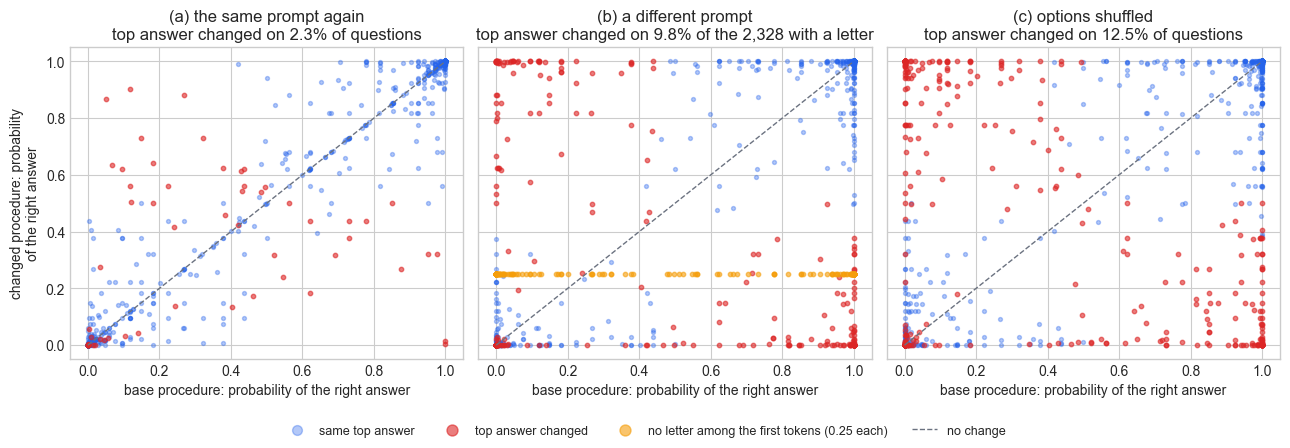

In [9]:
p_true_base = p_base[rows, y]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
for ax, (v, title) in zip(axes, [("rerun", "(a) the same prompt again"), ("altprompt", "(b) a different prompt"),
                                  ("shuffled", "(c) options shuffled")]):
    p_v = probs[v]
    # A placeholder row (no letter among the top-20 first tokens, 0.25 each) has no top answer:
    # argmax would invent "A". Mask those rows BEFORE counting changed answers.
    fallback = np.all(p_v == 0.25, axis=1)
    flip = (p_v.argmax(axis=1) != p_base.argmax(axis=1)) & ~fallback
    same, changed = ~flip & ~fallback, flip
    ax.scatter(p_true_base[same], p_v[same, y[same]], s=8, alpha=0.35, color=BLUE, label="same top answer")
    ax.scatter(p_true_base[changed], p_v[changed, y[changed]], s=10, alpha=0.6, color=RED,
               label="top answer changed")
    if fallback.any():
        ax.scatter(p_true_base[fallback], p_v[fallback, y[fallback]], s=10, alpha=0.6, color=AMBER,
                   label="no letter among the first tokens (0.25 each)")
    ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1, label="no change")
    scope = f" of the {(~fallback).sum():,} with a letter" if fallback.any() else " of questions"
    ax.set_title(f"{title}\ntop answer changed on {flip[~fallback].mean():.1%}{scope}")
    ax.set_xlabel("base procedure: probability of the right answer")
axes[0].set_ylabel("changed procedure: probability\nof the right answer")
handles, labels = axes[1].get_legend_handles_labels()       # panel (b) has all four kinds
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9, markerscale=2.5, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

In panel (a) almost every question sits on the diagonal or in the two corners (certain and right at the top right, certain and wrong at the bottom left), with a thin scatter of red questions whose top answer flipped. Panels (b) and (c) are visibly different procedures: far more questions leave the diagonal, and many jump from one corner to the other, which means the model was certain under both procedures and certain of different answers. The top answer changed on 9.8% of the questions where the new prompt produced a letter and on 12.5% under shuffling, about four and five times the noise floor of panel (a). Panel (b) also has a strange horizontal line of amber points at exactly 0.25: 185 questions for which the new prompt produced no letter at all, and therefore no answer. That is where the prompt change gets interesting.

In [10]:
# (b) A different prompt: no system message, the subject named, "Reply with A, B, C or D."
p_alt = probs["altprompt"]
alt_scores = 1.0 - p_alt[rows, y]
alt_mass = mcq["altprompt_letter_mass"].to_numpy()
# The generator falls back to 0.25 per option when not one of the 20 most likely first tokens
# is a letter: no information at all, and every option clears any bar below 0.75.
no_letter = np.all(p_alt == 0.25, axis=1)
has_letter = ~no_letter
# On the placeholder rows argmax would return "A" and invent an answer (right whenever the key
# is A), so the top answer and everything computed from it is restricted to rows with a letter.
alt_right = (p_alt.argmax(axis=1) == y) & has_letter
flip_alt = (p_alt.argmax(axis=1) != p_base.argmax(axis=1)) & has_letter
low_mass_by_subject = pd.Series(alt_mass < 0.5).groupby(mcq["subject"]).mean().sort_values(kind="mergesort")

print(f"no letter at all among the top-20 first tokens: {no_letter.sum()} questions "
      f"({no_letter[is_stem].sum()} of them STEM), {(no_letter & is_test).sum()} in the test half")
print(f"on the {has_letter.sum():,} questions with a letter: accuracy base prompt "
      f"{token_right[has_letter].mean():.3f}, new prompt {alt_right[has_letter].mean():.3f}; "
      f"top answer changed on {flip_alt[has_letter].mean():.1%}")
print(f"accuracy over all {n_q:,} questions, a missing letter counted as wrong: base {token_right.mean():.3f}, "
      f"new {alt_right.mean():.3f}")
print(f"median raw letter mass: base {mcq['base_letter_mass'].median():.3f}, new {np.median(alt_mass):.3f}; "
      f"questions with less than half the mass on A-D: base {(mcq['base_letter_mass'] < 0.5).sum()}, "
      f"new {(alt_mass < 0.5).sum()} ({np.mean(alt_mass < 0.5):.1%})")
print(f"   share by subject from {low_mass_by_subject.iloc[0]:.0%} ({low_mass_by_subject.index[0]}) "
      f"to {low_mass_by_subject.iloc[-1]:.0%} ({low_mass_by_subject.index[-1]})")

cov_alt, size_alt = set_report(p_alt, is_test, q_hat)
print(f"\ntest coverage with the base threshold: base prompt {cov_base:.3f}, new prompt {cov_alt:.3f}; "
      f"mean shortlist size {size_base:.2f} -> {size_alt:.2f}")
fallback_test = is_test & no_letter
answered = is_test & has_letter
cov_fb_base, size_fb_base = set_report(p_base, fallback_test, q_hat)
cov_fb_alt, size_fb_alt = set_report(p_alt, fallback_test, q_hat)
cov_ans_base, size_ans_base = set_report(p_base, answered, q_hat)
cov_ans_alt, size_ans_alt = set_report(p_alt, answered, q_hat)
print(f"   on the {fallback_test.sum()} fallback test questions: base {cov_fb_base:.3f} (size {size_fb_base:.2f}), "
      f"new {cov_fb_alt:.3f} (size {size_fb_alt:.2f})")
print(f"   on the {answered.sum()} other test questions:    base {cov_ans_base:.3f} (size {size_ans_base:.2f}), "
      f"new {cov_ans_alt:.3f} (size {size_ans_alt:.2f})")
lost, gained, p_sign = paired_test(covered_base, alt_scores <= q_hat, answered)
print(f"   right answer lost on {lost}, gained on {gained}; exact sign test p = {p_sign:.3f}")

q_hat_alt = corrected_quantile(alt_scores[is_cal], ALPHA)
cov_alt_recal, size_alt_recal = set_report(p_alt, is_test, q_hat_alt)
cov_ans_recal, size_ans_recal = set_report(p_alt, answered, q_hat_alt)
print(f"\nrecalibrated on the new prompt's own calibration answers: q_hat {q_hat_alt:.6f}, "
      f"test coverage {cov_alt_recal:.3f}, mean shortlist size {size_alt_recal:.2f}")
print(f"   on the {answered.sum()} test questions with letters: coverage {cov_ans_recal:.3f}, "
      f"mean shortlist size {size_ans_recal:.2f}")

no letter at all among the top-20 first tokens: 185 questions (138 of them STEM), 107 in the test half
on the 2,328 questions with a letter: accuracy base prompt 0.822, new prompt 0.811; top answer changed on 9.8%
accuracy over all 2,513 questions, a missing letter counted as wrong: base 0.797, new 0.751
median raw letter mass: base 1.000, new 0.995; questions with less than half the mass on A-D: base 8, new 865 (34.4%)
   share by subject from 0% (world_religions) to 97% (college_mathematics)

test coverage with the base threshold: base prompt 0.889, new prompt 0.889; mean shortlist size 1.37 -> 1.47
   on the 107 fallback test questions: base 0.748 (size 2.19), new 1.000 (size 4.00)
   on the 1150 other test questions:    base 0.902 (size 1.29), new 0.879 (size 1.24)
   right answer lost on 56, gained on 30; exact sign test p = 0.007

recalibrated on the new prompt's own calibration answers: q_hat 0.999930, test coverage 0.905, mean shortlist size 1.57
   on the 1150 test questions w

Overall, the prompt change costs set size, not coverage: with the base threshold, coverage on the test questions is 0.889 under both prompts, while the mean shortlist grows from 1.37 to 1.47 options. The answers themselves move more. On the 2,328 questions where the new prompt produced a letter, accuracy goes from 0.822 to 0.811 and the top answer changes on 9.8% of them; on the other 185 it produced no letter, and so no answer at all (count those as wrong and accuracy over the whole bank falls from 0.797 to 0.751). Had we stopped at the coverage aggregate, we would have said "costs set size, not coverage" and moved on. The aggregate, though, is two effects that happen to cancel, and the mechanism is a lesson about procedures.

Under the new prompt the model's first token was often not a letter. The median raw mass on A-D is still 0.995, but 865 questions (34.4%) put less than half of it there, against 8 under the base prompt, and the share runs from 0% in world religions to 97% in college mathematics. On 185 questions, 138 of them STEM, not one of the 20 most likely first tokens was a letter. The file stores only the letter mass, not the token, but the subject pattern suggests the model wanted to start a worked solution. For those questions the generator fell back to 0.25 per option, every option clears the bar, and 107 test questions received a four-option shortlist. Those shortlists cover by brute force (1.000, where the base procedure covered only 0.748 of these hard questions) and tell a student nothing. On the other 1,150 test questions the new prompt covers 0.879 where the base prompt covered 0.902 on the same questions: 56 lost the right answer and 30 gained it, and an exact sign test on those disagreements (McNemar's test) gives p = 0.007, unlikely to be noise. So the 0.889 is a small real loss of coverage hidden by 107 useless shortlists.

Recalibrating on the new prompt's own calibration answers restores the promise honestly: `q_hat` 0.999930, coverage 0.905 and shortlists of 1.57 options. They are longer than the base prompt's 1.37 mostly because the 107 fallback questions still receive all four options; on the 1,150 questions with letters the recalibrated shortlists average 1.35 options and cover 0.897. Two lessons. A prompt is part of the score, including the rule that turns the reply into numbers: a prompt that changes what the first token is changes what the probabilities mean. And an aggregate that does not move is not evidence that nothing changed. Recalibrate after every prompt change, and look underneath the headline number when you compare (field guide §25).

In [11]:
# (c) Options shown in a random order, probabilities mapped back to the original letters.
p_shuf = probs["shuffled"]
order = mcq["shuffled_order"].to_numpy()          # for each SHOWN position, the original letter
shuf_right = p_shuf.argmax(axis=1) == y
flip_shuf = p_shuf.argmax(axis=1) != p_base.argmax(axis=1)
shown_pos_right = np.array([order[i].index(mcq.at[i, "answer"]) for i in rows])
shown_pos_top = np.array([order[i].index(LETTERS[k]) for i, k in zip(rows, p_shuf.argmax(axis=1))])
cov_shuf, size_shuf = set_report(p_shuf, is_test, q_hat)

unshuffled = order == "ABCD"      # by chance the original order: the base prompt and settings a third time
print(f"top answer changed: {flip_shuf.sum()} questions ({flip_shuf.mean():.1%}), against {flip_rerun.mean():.1%} "
      f"for the base prompt sent twice")
print(f"orders that happen to equal the original A-D: {unshuffled.sum()}; top answer changed on "
      f"{flip_shuf[unshuffled].sum()} of them ({flip_shuf[unshuffled].mean():.1%})")
print(f"accuracy {token_right.mean():.3f} -> {shuf_right.mean():.3f}: right -> wrong on "
      f"{(token_right & ~shuf_right).sum()}, wrong -> right on {(~token_right & shuf_right).sum()}")
print(f"test coverage with the base threshold: {cov_shuf:.3f} (base {cov_base:.3f}); "
      f"mean shortlist size {size_shuf:.3f} (base {size_base:.3f})")
covered_shuf = (1.0 - p_shuf[rows, y]) <= q_hat
for label, mask in [("test half", is_test), ("all questions", np.ones(n_q, dtype=bool))]:
    lost, gained, p_sign = paired_test(covered_base, covered_shuf, mask)
    print(f"   {label}: right answer lost on {lost}, gained on {gained}; exact sign test p = {p_sign:.3f}")

# Position effects. Accuracy by where the right answer was shown: a 4 x 2 table, valid because the
# shown position of the right answer was assigned at random.
chi2_acc = chi2_contingency(pd.crosstab(shown_pos_right, shuf_right))
# Where do WRONG top answers land? If position did not matter, each would sit at any of the three
# positions not holding the right answer with probability 1/3.
wrong_shuf = ~shuf_right
observed = np.bincount(shown_pos_top[wrong_shuf], minlength=4)
expected = np.array([np.sum(wrong_shuf & (shown_pos_right != k)) / 3 for k in range(4)])
fit_wrong = chisquare(observed, f_exp=expected)
print(f"accuracy depends on where the right answer is shown? chi-square p = {chi2_acc.pvalue:.3f}")
print(f"wrong top answers spread evenly over the positions not holding the right answer? "
      f"chi-square p = {fit_wrong.pvalue:.3f}")
position = pd.DataFrame({
    "right answer shown here": np.bincount(shown_pos_right, minlength=4) / n_q,
    "accuracy when the right answer is shown here": [shuf_right[shown_pos_right == k].mean() for k in range(4)],
    "wrong top answers shown here": observed,
    "expected if position did not matter": expected,
}, index=pd.Index(LETTERS, name="shown position"))
position.round({"right answer shown here": 3, "accuracy when the right answer is shown here": 3,
                "expected if position did not matter": 1})

top answer changed: 313 questions (12.5%), against 2.3% for the base prompt sent twice
orders that happen to equal the original A-D: 108; top answer changed on 1 of them (0.9%)
accuracy 0.797 -> 0.802: right -> wrong on 121, wrong -> right on 132
test coverage with the base threshold: 0.901 (base 0.889); mean shortlist size 1.375 (base 1.370)
   test half: right answer lost on 26, gained on 42; exact sign test p = 0.068
   all questions: right answer lost on 72, gained on 88; exact sign test p = 0.236
accuracy depends on where the right answer is shown? chi-square p = 0.036
wrong top answers spread evenly over the positions not holding the right answer? chi-square p = 0.046


,right answer shown here,accuracy when the right answer is shown here,wrong top answers shown here,expected if position did not matter
shown position,,,,
A,0.253,0.822,155,128.3
B,0.244,0.780,107,121.0
C,0.260,0.778,108,117.7
D,0.243,0.828,128,131.0


Shuffling the options moved the top answer on 313 questions (12.5%), five times the 2.3% that asking again produced. The data even contains a control: on 108 questions the random order happened to be the original A-D, so the shuffled run sent the base prompt with the base settings a third time, and its top answer changed on 1 of them (0.9%), in line with the noise floor. Accuracy went from 0.797 to 0.802 (121 questions went from right to wrong and 132 from wrong to right), and coverage with the base threshold is 0.901, with shortlists of the same size (1.375 options against 1.370).

Is 0.901 against 0.889 a real gain? On the test half, the shuffled procedure lost the right answer on 26 questions and gained it on 42, and the exact sign test gives p = 0.068, suggestive at most. Over all 2,513 questions the same comparison is 72 against 88 (p = 0.236), and the rerun leaned the same way on this test half (9 against 13). The test-half lean is consistent with this split's slightly unlucky base coverage of 0.889, if part of that bad luck lies in the base run's answers: a fresh draw of the answers would then be expected to win back some of the questions the base run happened to miss. The other part, which questions landed in the test half, no redraw of the answers changes. So across the bank the option order makes no detectable difference to coverage, while for individual questions it matters a great deal: one question in eight gets a different answer depending only on where its options sit.

The position effects are mild. Accuracy is 0.822 and 0.828 when the right answer is shown first or last and 0.780 and 0.778 in the two middle positions (chi-square p = 0.036). The cleaner test looks at where wrong answers land. A wrong top answer lands on the first shown position 155 times where 128.3 would be expected if position did not matter (p = 0.046), and on each of the other positions no more often than expected. That is weak evidence of a slight preference for the first position, small next to the churn itself.

What this means for **contamination**, benchmark questions present in the model's training data. MMLU has been public since 2020, so some of these questions may well be in `gpt-4.1-mini`'s training data; we cannot check that from outside. A shuffle is a cheap probe of one kind of memorization: a model that had memorized "the answer to this question is C" would lose accuracy when C moves. Accuracy did not drop, so there is no sign of letter memorization here. The shuffle cannot rule out the other kind, memorizing the content of the right answer, which survives any reordering. That is the deeper reason why a coverage number measured on a public benchmark is a rehearsal, not a promise about Quill's students: their questions are not the benchmark (field guide §26). And even inside the benchmark, the population matters more than anything we have changed so far.

In [12]:
# (d) A different population. First the head of learning's number, by subject group.
for level in (90, 95, 100):
    at = stated_conf == level / 100
    print(f"stated {level}: right {stated_right[at].mean():.3f} of {at.sum()} answers; "
          f"non-STEM {stated_right[at & ~is_stem].mean():.3f} ({(at & ~is_stem).sum()}), "
          f"STEM {stated_right[at & is_stem].mean():.3f} ({(at & is_stem).sum()})")
print(f"mean stated confidence: non-STEM {100 * stated_conf[~is_stem].mean():.1f}, STEM "
      f"{100 * stated_conf[is_stem].mean():.1f}; accuracy of the stated answer: non-STEM "
      f"{stated_right[~is_stem].mean():.3f}, STEM {stated_right[is_stem].mean():.3f}")

# Then the conformal threshold: calibrate on one mix (calibration half), deploy on another (test half).
# The last rows are a stress test chosen WITH HINDSIGHT: the 14 subjects with the lowest accuracy.
# Chosen on all labels, the choice also sees the calibration half (selection pulls q_hat down);
# chosen on the test half's labels only, it does not.
hard = set(subject_acc.index[:14])
is_hard = mcq["subject"].isin(hard).to_numpy()
acc_test_only = (pd.Series(token_right[is_test]).groupby(mcq["subject"].to_numpy()[is_test]).mean()
                 .sort_values(kind="mergesort"))
is_hard_t = mcq["subject"].isin(set(acc_test_only.index[:14])).to_numpy()


def mix_row(deployed, calibrated, cal_mask, test_mask):
    q = corrected_quantile(base_scores[cal_mask], ALPHA)
    cov, size = set_report(p_base, test_mask, q)
    return {"deployed on": deployed, "calibrated on": calibrated, "n calibration": int(cal_mask.sum()),
            "n test": int(test_mask.sum()), "q_hat": q, "coverage": cov, "mean set size": size,
            "test accuracy": token_right[test_mask].mean()}


mix = pd.DataFrame([
    mix_row("STEM", "non-STEM", is_cal & ~is_stem, is_test & is_stem),
    mix_row("STEM", "all subjects (section 3)", is_cal, is_test & is_stem),
    mix_row("STEM", "STEM", is_cal & is_stem, is_test & is_stem),
    mix_row("non-STEM", "STEM", is_cal & is_stem, is_test & ~is_stem),
    mix_row("non-STEM", "all subjects (section 3)", is_cal, is_test & ~is_stem),
    mix_row("non-STEM", "non-STEM", is_cal & ~is_stem, is_test & ~is_stem),
    mix_row("14 hardest (hindsight)", "14 easiest", is_cal & ~is_hard, is_test & is_hard),
    mix_row("14 hardest (hindsight)", "14 hardest", is_cal & is_hard, is_test & is_hard),
    mix_row("14 hardest (test labels)", "14 easiest (test labels)", is_cal & ~is_hard_t, is_test & is_hard_t),
])
print(f"\nnoise band for {int(mix.loc[0, 'n test'])} STEM test questions: "
      f"+/- {2 * math.sqrt(ALPHA * (1 - ALPHA) / mix.loc[0, 'n test']):.3f}")
mix.round({"q_hat": 6, "coverage": 3, "mean set size": 2, "test accuracy": 3})

stated 90: right 0.742 of 449 answers; non-STEM 0.749 (386), STEM 0.698 (63)
stated 95: right 0.818 of 1654 answers; non-STEM 0.884 (1031), STEM 0.709 (623)
stated 100: right 0.850 of 294 answers; non-STEM 0.955 (88), STEM 0.806 (206)
mean stated confidence: non-STEM 93.4, STEM 95.8; accuracy of the stated answer: non-STEM 0.834, STEM 0.731

noise band for 457 STEM test questions: +/- 0.028


,deployed on,calibrated on,n calibration,n test,q_hat,coverage,mean set size,test accuracy
0,STEM,non-STEM,813,457,0.995930,0.842,1.42,0.731
1,STEM,all subjects (section 3),1256,457,0.998830,0.856,1.50,0.731
2,STEM,STEM,443,457,0.999765,0.880,1.60,0.731
3,non-STEM,STEM,443,800,0.999765,0.919,1.37,0.828
4,non-STEM,all subjects (section 3),1256,800,0.998830,0.908,1.30,0.828
5,non-STEM,non-STEM,813,800,0.995930,0.896,1.25,0.828
6,14 hardest (hindsight),14 easiest,627,631,0.622460,0.702,1.02,0.694
7,14 hardest (hindsight),14 hardest,629,631,0.999981,0.892,1.84,0.694
8,14 hardest (test labels),14 easiest (test labels),623,627,0.952574,0.767,1.26,0.689


Here is the head of learning's question answered with data, and the answer to its second half is no. When Quill says 95, it is right 0.818 of the time across the whole bank, but 0.884 on non-STEM subjects and 0.709 on STEM. Its stated confidence is higher on STEM (95.8 on average against 93.4), where it is less accurate (0.731 against 0.834). A "95" measured on history and law does not transfer to mathematics; it does not even point in the right direction.

The conformal threshold tells the same story through coverage. Picture Quill launching with the non-STEM question banks, calibrated on their 813 calibration questions, and then the mathematics and science departments signing up. On the 457 STEM test questions that threshold covers 0.842, well outside the noise band of plus or minus 0.028. Calibrating on the mixed bank of section 3 gives 0.856, and calibrating on STEM questions themselves gives 0.880 (from 443 calibration questions: inside the noise band, and the calibration draw adds its own lottery). The closer the calibration mix is to the deployment mix, the closer coverage comes to the promise. In the other direction, the STEM threshold over-covers non-STEM questions (0.919) and pays in set size (1.37 options against 1.25 with their own threshold).

The hindsight stress test shows the magnitude a bad mix can reach. Calibrate on the 14 subjects where Quill is most accurate and deploy on the other 14: `q_hat` falls to 0.622, so an option needs a probability of 0.378 to make the list, shortlists shrink to 1.02 options, and coverage collapses to 0.702, barely above the hard subjects' accuracy of 0.694. The easy subjects' calibration taught the threshold that Quill's top answer is almost always enough, and on hard subjects it is not. Calibrated on the hard subjects themselves, the same test questions are covered at 0.892 with shortlists of 1.84 options. We chose the 14 subjects using every question's label, which a real deployment could not do, and that choice also leans on the calibration half: subjects whose calibration questions happened to go well are more likely to be called easy, which pulls `q_hat` down. Choosing the 14 subjects from the test half's labels alone (the last row) removes that part, and coverage on the hard subjects is 0.767 with `q_hat` 0.952574. So read 0.702 to 0.767 as the size the effect can reach, not as a forecast.

Notebook 09 asked at which level the shuffle is plausible. For Quill the natural level is the subject: a new subject (a new course signing up) is a new building in notebook 09's portfolio. The next cell runs notebook 09's leave-one-out experiment with subjects in place of buildings: calibrate on all questions of 27 subjects, then measure coverage on the 28th.

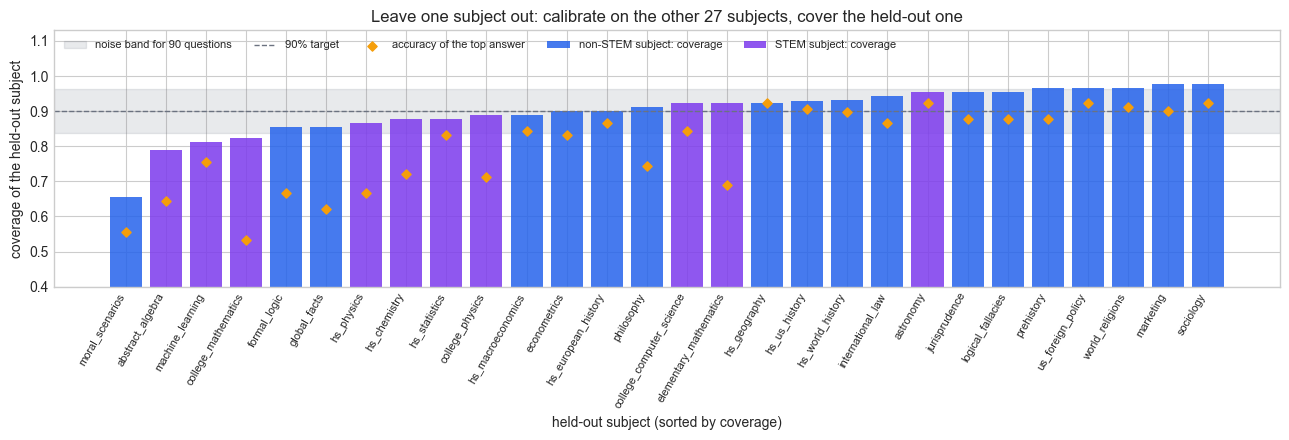

mean coverage over 28 held-out subjects: 0.900; range 0.656 (moral_scenarios) to 0.978 (marketing, sociology)
subjects below 0.90: 11; below the noise band (0.837): 4; above it (0.963): 5
subjects outside the band: 9; expected from binomial noise alone: 1.4
probability an option needs to join the shortlist, across the 28 folds: 0.0005 to 0.0015
                        coverage  mean set size  accuracy
subject                                                  
elementary_mathematics     0.922          1.667     0.689
machine_learning           0.811          1.211     0.756
moral_scenarios            0.656          1.333     0.556


In [13]:
loso = []
for subject in sorted(mcq["subject"].unique()):
    held = (mcq["subject"] == subject).to_numpy()
    q = corrected_quantile(base_scores[~held], ALPHA)
    cov, size = set_report(p_base, held, q)
    loso.append({"subject": subject, "STEM": subject in MMLU_STEM, "n": int(held.sum()), "coverage": cov,
                 "mean set size": size, "accuracy": token_right[held].mean(), "entry bar": 1 - q})
loso = pd.DataFrame(loso).sort_values(["coverage", "subject"], kind="mergesort").reset_index(drop=True)
band = 2 * math.sqrt(ALPHA * (1 - ALPHA) / 90)

fig, ax = plt.subplots(figsize=(13, 4.5))
x = np.arange(len(loso))
ax.axhspan(1 - ALPHA - band, 1 - ALPHA + band, color=GRAY, alpha=0.15, label="noise band for 90 questions")
ax.axhline(1 - ALPHA, color=GRAY, linestyle="--", linewidth=1, label="90% target")
for stem, color, label in [(False, BLUE, "non-STEM subject: coverage"), (True, PURPLE, "STEM subject: coverage")]:
    sel = (loso["STEM"] == stem).to_numpy()
    ax.bar(x[sel], loso.loc[sel, "coverage"], color=color, alpha=0.85, label=label)
ax.scatter(x, loso["accuracy"], marker="D", s=22, color=AMBER, zorder=3, label="accuracy of the top answer")
ax.set_xticks(x)
ax.set_xticklabels(loso["subject"].str.replace("high_school_", "hs_"), rotation=60, ha="right", fontsize=8)
ax.set_ylim(0.4, 1.13)
ax.set_title("Leave one subject out: calibrate on the other 27 subjects, cover the held-out one")
ax.set_xlabel("held-out subject (sorted by coverage)")
ax.set_ylabel("coverage of the held-out subject")
ax.legend(loc="upper left", fontsize=8, ncol=5)
plt.tight_layout()
plt.show()

print(f"mean coverage over 28 held-out subjects: {loso['coverage'].mean():.3f}; range "
      f"{loso['coverage'].min():.3f} ({loso.loc[0, 'subject']}) to {loso['coverage'].max():.3f} "
      f"({', '.join(loso.loc[loso['coverage'] == loso['coverage'].max(), 'subject'])})")
print(f"subjects below 0.90: {(loso['coverage'] < 0.90).sum()}; below the noise band "
      f"({1 - ALPHA - band:.3f}): {(loso['coverage'] < 1 - ALPHA - band).sum()}; above it "
      f"({1 - ALPHA + band:.3f}): {(loso['coverage'] > 1 - ALPHA + band).sum()}")
# How many subjects would land outside the band from binomial noise alone, if every subject's
# true coverage were exactly 0.90? (Ignores the small wobble of a 2,400-question calibration set.)
lo_band, hi_band = 1 - ALPHA - band, 1 - ALPHA + band
noise_only = sum(binom.cdf(math.ceil(m * lo_band) - 1, m, 1 - ALPHA) + binom.sf(math.floor(m * hi_band), m, 1 - ALPHA)
                 for m in loso["n"])
print(f"subjects outside the band: {((loso['coverage'] < lo_band) | (loso['coverage'] > hi_band)).sum()}; "
      f"expected from binomial noise alone: {noise_only:.1f}")
print(f"probability an option needs to join the shortlist, across the 28 folds: "
      f"{loso['entry bar'].min():.4f} to {loso['entry bar'].max():.4f}")
print(loso.set_index("subject").loc[["elementary_mathematics", "machine_learning", "moral_scenarios"],
                                    ["coverage", "mean set size", "accuracy"]].round(3).to_string())

Averaged over the 28 held-out subjects, coverage is 0.900: a new subject drawn the way these were drawn gets the 90% promise on average, approximately, just as notebook 09's pooled buildings did. Any single subject gets a lottery ticket and a slice (notebook 03): coverage runs from 0.656 for moral scenarios to 0.978 for marketing and sociology, 11 of the 28 subjects fall below 0.90, 4 fall below the noise band for 90 questions (0.837) and 5 sit above it. If every subject's true coverage were exactly 0.90, binomial noise alone would put about 1.4 subjects outside that band, not 9: these are real differences between subjects, not sampling noise. That is notebook 09's portfolio of buildings again, field guide §13 with subjects in place of sites.

The bars do not follow the accuracy markers, and the reason is worth a sentence. In every fold an option needs only a tiny probability to join the shortlist (between 0.0005 and 0.0015, printed above), so coverage is the share of questions on which the model did not all but rule out the right answer: what costs coverage is being confidently wrong, not being wrong. Elementary mathematics is one of the seven least accurate subjects (0.689) and is covered at 0.922, because its errors are hesitant and its shortlists widen (1.67 options on average). Machine learning is more accurate (0.756) and covered only at 0.811, because its errors are confident. Moral scenarios is both inaccurate and confident, and lands at 0.656. A promise per subject needs calibration per subject, and notebook 17 (section 5) builds it.

Here is section 4 in one table. Coverage is measured on the 1,257 test questions with the base threshold unless the row says otherwise; the base procedure covers 0.889 with shortlists of 1.37 options.

| What changed | Top answer changed | Coverage | Mean shortlist | What it means |
|---|---|---|---|---|
| nothing: the same prompt and settings again | 2.3% | 0.892 | 1.38 | randomness inside the procedure; calibration already saw it, so the promise holds on average (sign test p = 0.523) and individual answers still flip |
| the prompt | 9.8% of the 2,328 questions with a letter; no letter on 185 | 0.889, but 0.879 against 0.902 where the prompt produced letters (p = 0.007) | 1.47 | a new procedure that changed what the probabilities measure; recalibrated: 0.905 with 1.57 options |
| the option order | 12.5% | 0.901 | 1.38 | no detectable change across the bank (p = 0.236), a different answer for one question in eight |
| the subject mix: non-STEM calibration, STEM questions | - | 0.842 | 1.42 | a new population, the largest real-world effect we measured |
| the subject mix: easiest half calibrates, hardest half deployed (hindsight) | - | 0.702 (0.767 with subjects chosen on test labels only) | 1.02 | how far a bad mix can push it |
| one subject held out, the other 27 calibrate | - | 0.656 to 0.978 (mean 0.900) | - | the promise lives at the level of subjects on average, not for any one subject |

The pitfall to take away: none of these changes raised an error, and the two that did the most damage, the prompt and the population, are the two that product teams change most casually.

## 5. The calibration record

Every number in this notebook can be traced to a request, because the generator logged its settings and cached every reply. Production calibration needs the same discipline, for the reason section 4 measured: a calibration is evidence about one procedure, and the record is how anyone, including you in six months, knows which one. Below is the record of this notebook's own calibration run, assembled from `generation_log.json`, the generator's settings and the numbers measured above. Each line says why it is logged, with the measurement from this notebook that justifies it.

In [14]:
# The base prompt, as the generator built it (llm_data/generate_llm_data.ipynb). Hashing the
# template text makes "the prompt changed" a checkable fact instead of a memory.
BASE_SYSTEM = "You are an expert answering multiple-choice exam questions."
BASE_USER = "Question: {question}\n{options}\nAnswer with the letter of the correct option only."
prompt_hash = hashlib.sha256((BASE_SYSTEM + "\n" + BASE_USER).encode()).hexdigest()[:12]

# The model version every chat response reported, as counted in the rebuilt generation log.
chat_versions = [k.split(": ", 1)[1] for k in generation_log["response_models"] if k.startswith("chat: ")]
assert len(chat_versions) == 1, "every chat response should report the same model version"

record = pd.DataFrame([
    ("model", f"deployment {generation_log['chat_deployment']}, Azure OpenAI; version {chat_versions[0]}",
     "a provider can update the model behind an unchanged deployment name"),
    ("API version", generation_log["api_version"], "request and response formats change between versions"),
    ("prompt template", f"system + user template, sha256 {prompt_hash}",
     f"a new prompt changed the top answer on {flip_alt[has_letter].mean():.1%} where it gave a letter, "
     f"gave none on {no_letter.sum()}, needed its own threshold"),
    ("decoding", f"temperature 0, max_tokens 1, top_logprobs 20, seed {generation_log['random_seed']}",
     "the score is only defined for these settings"),
    ("score extraction", "first token's log-probabilities of A-D in any token form (' A', 'a', 'A.', ...), "
                         "renormalized; 0 outside the top 20; 0.25 each if none is in it",
     f"under the new prompt {no_letter.sum()} questions had no letter in the top 20"),
    ("option order", "as published (A-D)", f"shuffling changed the top answer on {flip_shuf.mean():.1%}"),
    ("repeatability", f"base prompt and settings sent twice: top answer changed on {flip_rerun.mean():.1%}",
     "the noise floor every other comparison is judged against"),
    ("date", generation_log["generated_on"], "a hosted model can change behind an unchanged name"),
    ("population", f"{n_q:,} MMLU questions, {mcq['subject'].nunique()} subjects, {is_stem.sum()} of them STEM",
     f"non-STEM calibration covered STEM at {mix.loc[0, 'coverage']:.3f}; single subjects "
     f"{loso['coverage'].min():.3f} to {loso['coverage'].max():.3f}"),
    ("split and level", f"random 50/50, seed {RANDOM_SEED}; alpha {ALPHA}; {is_cal.sum()} calibration questions",
     "the lottery: 1,000 other splits ranged "
     f"{np.percentile(lottery, 5):.3f} to {np.percentile(lottery, 95):.3f} (5th to 95th percentile)"),
    ("result", f"q_hat {q_hat:.6f}; coverage {cov_base:.3f}; mean shortlist {size_base:.2f}",
     "what the next calibration run is compared with"),
], columns=["field", "value in this notebook", "why it is logged (measured here)"])
with pd.option_context("display.max_colwidth", 150):
    display(record.set_index("field"))

,value in this notebook,why it is logged (measured here)
field,,
model,"deployment gpt-4.1-mini, Azure OpenAI; version gpt-4.1-mini-2025-04-14",a provider can update the model behind an unchanged deployment name
API version,2025-04-01-preview,request and response formats change between versions
prompt template,"system + user template, sha256 9c5172c3610a","a new prompt changed the top answer on 9.8% where it gave a letter, gave none on 185, needed its own threshold"
decoding,"temperature 0, max_tokens 1, top_logprobs 20, seed 20260707",the score is only defined for these settings
score extraction,"first token's log-probabilities of A-D in any token form (' A', 'a', 'A.', ...), renormalized; 0 outside the top 20; 0.25 each if none is in it",under the new prompt 185 questions had no letter in the top 20
option order,as published (A-D),shuffling changed the top answer on 12.5%
repeatability,base prompt and settings sent twice: top answer changed on 2.3%,the noise floor every other comparison is judged against
date,2026-11-07,a hosted model can change behind an unchanged name
population,"2,513 MMLU questions, 28 subjects, 900 of them STEM",non-STEM calibration covered STEM at 0.842; single subjects 0.656 to 0.978


Three habits make a record like this useful rather than ceremonial. First, hash what can be hashed (the prompt template, the extraction code), so that "nothing changed" is a comparison of two strings rather than a recollection. Second, log the repeatability measurement next to the result: a 2.3% flip rate for the same prompt and settings sent twice is the yardstick that told us the prompt's 9.8% (on the questions where it produced a letter at all) and the shuffle's 12.5% were real changes. Third, log the population as precisely as the model, because in section 4 the population did more damage than any setting.

One line of this record took a second pass. The first generation log named only the deployment, `gpt-4.1-mini`, not the model version behind it, and a provider can update the model under an unchanged name. The version had to be recovered from the replies themselves, which report `gpt-4.1-mini-2025-04-14`, and the rebuilt log now records it for every response (`response_models`), which is where the record above reads it. That is the line to close first in production: store the model version string the API returns next to every calibration run, re-run a fixed probe set after any announced update, and until both are in place say so in the report, because the guarantee inherits the uncertainty.

## 6. Common mistakes to avoid

1. **Reading stated confidence as a probability.** Quill's "95" was right 0.818 of the time overall, 0.884 on non-STEM subjects and 0.709 on STEM, and stated confidence barely ranks answers (AUROC 0.576). Draw the reliability diagram before printing any confidence number to a student (field guide §24).
2. **Judging a confidence score by its calibration error alone.** Stated confidence had the lowest ECE of the three readings (0.146) and the worst ranking; a constant 0.797 has an ECE of 0.000 and ranks nothing. Any score keeps the conformal promise, but only a score that ranks keeps the shortlists short, so report AUROC, and later set size, next to ECE (field guide §24, field guide §5).
3. **Treating a calibrated probability as a promise about one question.** Calibration describes groups of past answers, on one population: the perfectly calibrated constant was off by up to 26.4 points within a subject. A conformal shortlist carries a promise at a level you choose, under exchangeability (field guide §3).
4. **Believing that temperature 0 makes a hosted model deterministic.** With temperature 0 and a fixed seed, the same prompt and settings sent twice changed the top answer on 2.3% of questions, and one probability moved by 0.996. Measure repeatability and log it with every calibration run (field guide §25).
5. **Editing the prompt and keeping the threshold.** Coverage stayed at 0.889 only because 107 test questions received four-option shortlists; where the new prompt produced letters, coverage fell from 0.902 to 0.879. Recalibrate after any change to the prompt, the template or the extraction rule, and look beneath the aggregate (field guide §25).
6. **Calibrating on one population and quoting the result for another.** Non-STEM calibration covered STEM questions at 0.842, the hindsight easy-to-hard split at 0.702, and single held-out subjects ranged from 0.656 to 0.978. Calibrate on a labelled sample of the traffic you will serve, at the level you will quote (field guide §26, field guide §13).
7. **Reading a clean shuffle test as proof that the benchmark is not contaminated.** Shuffling probes letter memorization only; memorized content survives any reordering. Treat benchmark coverage as a rehearsal (field guide §26).
8. **Calibrating without a record.** A threshold without its model version, prompt hash, decoding settings, option order, date and population cannot be checked against the procedure that is running today (field guide §25).

## 7. What to say in the product review

**Strong version**

> "Quill's three confidence readings are all overconfident on our 2,513-question MMLU bank: answers that are right 80% of the time come with an average token probability of 0.96 and a stated confidence of 94%, and a stated '95' means 0.88 on non-STEM subjects and 0.71 on STEM. We therefore do not present any of these numbers as a probability. We use the token probabilities only to rank options: a conformal threshold calibrated on 1,256 questions gives shortlists of 1.37 options on average that contained the right answer for 0.889 of 1,257 held-out questions (1,000 random splits average 0.900). The promise belongs to one procedure, which we log: the gpt-4.1-mini deployment (version gpt-4.1-mini-2025-04-14), the prompt hash, temperature 0 with one token, options in published order, the date and the subject mix. Sending the same prompt twice changed 2.3% of answers without hurting coverage. A new prompt kept headline coverage at 0.889 only because 107 questions received four-option shortlists, so we recalibrate after every prompt change. The largest risk is the population: a threshold calibrated on non-STEM subjects covered STEM questions at 0.842, so before quoting any number to a department we calibrate on a labelled sample of that department's own questions."

**Weak version**

> "The model is 80% accurate on MMLU and reports 95% confidence, so its confidence is a reasonable guide for students. We run it at temperature 0, which makes it deterministic, and we validated 90% coverage of the shortlists on MMLU, so Quill's shortlists contain the right answer 90% of the time for our students in every subject."

The weak version treats a stated number as a probability after the data showed it is neither calibrated nor informative, assumes a determinism the rerun disproved, and quotes a benchmark result for a different population, in every subject, when single subjects ranged from 0.656 to 0.978. It also never says which procedure the 90% belongs to, so nobody could tell when it stopped applying. The strong version separates description from promise, names the procedure, quotes the measured sensitivity to each change, and says what happens before the promise is extended to a new population.

### The one-line summary

A language model reports certainty in three ways, and on Quill's question bank all three overstated the hit rate by 15 to 17 points; stated confidence crowded at 95 and barely ranked answers, while token probabilities ranked them well enough to keep a 90% shortlist short without being calibrated at all. That shortlist is a promise about one procedure. Asking again moved individual answers but not coverage; a new prompt hid a real coverage loss behind useless four-option sets; shuffling changed one answer in eight; and a new subject mix broke the promise outright. Freeze the procedure, measure how much it wobbles, and calibrate on the questions you will actually serve.

A model's confidence is a property of the whole procedure, not of the model.